<h1 style="text-align: center"> Automobile Fuel Efficiency Prediction </h1>

The Auto MPG Dataset from UCI Machine Learning Repository provides an excellent foundation for analyzing the key technical factors that influence vehicle fuel efficiency. This project combines feature analysis with statistical prediction: using machine learning models to uncover how vehicle features such as engine displacement, horsepower, vehicle weight, and cylinder count contribute to fuel performance outcomes.

---

## Section 1 | Initial Data Analysis

In [1]:
# import required libraries
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from feature_engine.imputation import DropMissingData
from feature_engine.preprocessing import MatchCategories
from pyampute.exploration.mcar_statistical_tests import MCARTest
from ucimlrepo import fetch_ucirepo

### Data Specification

*The first step in data analysis is to set out a full and detailed [specification](https://en.wikipedia.org/wiki/Data_preparation#Data_specification) of the format of each data field and what the entries mean. This especially take careful account of a full understanding of the information—and any gaps available—in the source data.*

#### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Features | 7 |
| Data Types | Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Categorical, Integer |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by Quinlan (1993) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes (Quinlan, 1993).

#### Data ETL

In [2]:
def data_etl(id):
    """Fetches data from the UCI repository and prepares it for analysis.
    
    Args:
        id (int): The identifier for the dataset to be fetched from the UCI repository.
    
    Returns:
        pd.DataFrame: A DataFrame containing the features and target variables of the dataset.
    """
    ucirepo_dotdict = fetch_ucirepo(id=id)

    features = ucirepo_dotdict.data.features
    target = ucirepo_dotdict.data.targets

    columns = 1
    dataset = pd.concat([features, target], axis=columns)

    return dataset

* *[Extract, transform, load (ETL)](https://en.wikipedia.org/wiki/Extract,_transform,_load) is a three-phase computing process where data is extracted from an input source, transformed (to the appropriate format), and loaded into an output data container—or in this case, a variable instance.*
* *The table below displays 5 sample rows from the dataset which represents the ETL result.*

In [3]:
# fetch dataset
id_auto_mpg = 9
data = pd.DataFrame(data_etl(id=id_auto_mpg))

# show dataset samples
n_samples = 5
data.sample(n=n_samples)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
187,305.0,8,140.0,4215,13.0,76,1,17.5
299,141.0,4,71.0,3190,24.8,79,2,27.2
151,79.0,4,67.0,2000,16.0,74,2,31.0
232,351.0,8,149.0,4335,14.5,77,1,16.0
231,400.0,8,190.0,4325,12.2,77,1,15.5


* Each row in the dataframe represents a single instance from the car samples.
* The columns in the dataframe are variables that represent the diversity of each sample.
    * Some columns act as *features*, which are the independent variables used as input to a machine learning model, and
    * The first column is the *target*, which is the variable that corresponds to the input data.
* *The `car_name` column is not included in the fetching process provided by the UCI ML Repository, but it can be accessed by downloading the raw data from the [source URL](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) and opening the `auto-mpg.data` file.*

#### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | _Weight**_ | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | _19xx**_ | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type (unique for each instance)* | - | <center> No </center> |

</div>

***Diasumsikan sebagai curb weight, dan car model year in the seventies and eighties respectively berdasarkan observasi terhadap sampel dataset*

Based on these descriptions and prior to observing the complete samples of Auto MPG dataset, it stands to reason for including all of these potentially informative feature variables in predicting target variable `mpg` as the main objective of this project.

### Data Inspection

In [4]:
# perform initial inspection on dataset
def data_inspect(data):
    inspection_summary = pd.DataFrame({
        "dtype": data.dtypes,
        "sample": [data[column].unique() for column in data.columns],
        "min": [data[column].min() for column in data.columns],
        "max": [data[column].max() for column in data.columns],
        "duplicated": data.duplicated().sum(),
        "missing": data.isna().sum()
    })

    return inspection_summary

In [5]:
data_inspect(data)

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0,0,0
cylinders,int64,"[8, 4, 6, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0,0,6
weight,int64,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0,0,0
acceleration,float64,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8,0,0
model_year,int64,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6,0,0


* The `dtype` column shows the data types in `data_train`, all of which are `float` and `int`:
    * These data types represent the random `sample` shown for each variable. For example, `mpg` contains decimal values such as `17.5`.
    * `float` indicates a numerical continuous variable, while `int` indicates a numerical discrete variable.
        * The true nature of the `weight` variable is conceptually *continuous*—even if recorded as whole numbers—since it varies smoothly in reality and the measurement resolution in this case is arbitrary.
        * Notably, the target variable `mpg` is at the *ratio* level; a true zero exists for this variable, which represents the absence of any fuel efficiency.
        * Domain knowledge indicates that the `origin` variable has an **invalid data type** and should instead be [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* In general, no invalid data issues were detected:
    * The value ranges shown in the `min` and `max` columns, according to domain knowledge, represent valid, reasonable, and realistic values for the car samples.
    * For example, in the `displacement` column, a car's engine displacement can range from `70.0` to `455.0` cubic inches.
* The data inspection process also includes detection of `duplicated` and `missing` data:
    * No duplicated data were detected, as shown by the `duplicated` column values being `0` across all variables, but
    * **Missing data** was detected in the `horsepower` variable:
        * As shown in the `missing` column, the `horsepower` variable has a value of `6`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.

#### Invalid Data Type

In [6]:
# encode selected variables in dataset to Pandas' "categorical" data type
invalid_column = "origin"
transformer = MatchCategories(
    invalid_column,
    ignore_format=True # allow transformer on variables with non-string data type (e.g., numeric)
)
data_matched = pd.DataFrame(
    transformer.fit_transform(data),
    columns=transformer.get_feature_names_out()
)

The `origin` variable, with a nominal data type, is also part of the categorical data type family. Therefore, the `MatchCategories()` transformer can be used to convert this variable into a suitable categorical representation for later modeling steps.

#### Missing Data

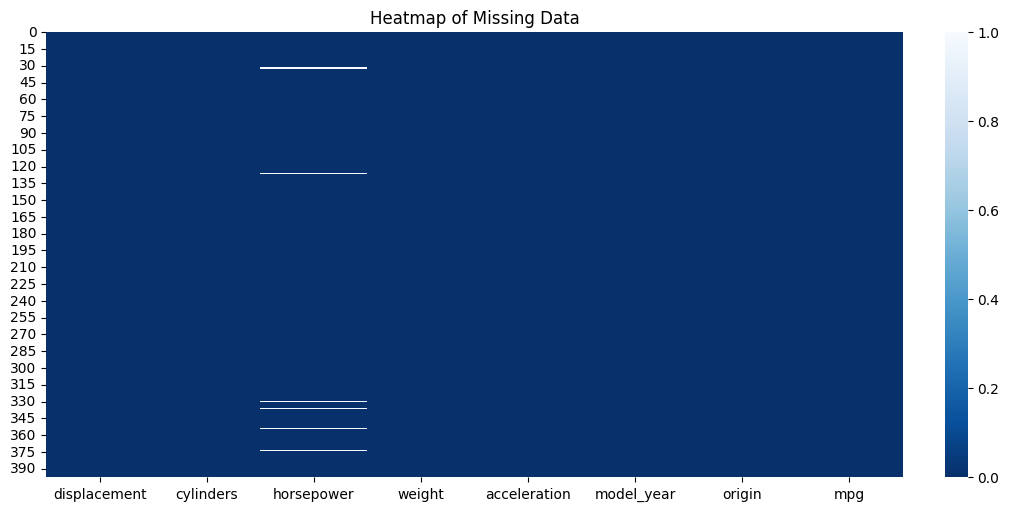

In [7]:
# visualize missing data pattern
width, height = 10, 5
plt.figure(figsize=(width, height), layout="constrained")

sns.heatmap(
    data_matched.isna().sort_index(),
    cmap="Blues_r" # reverse color map for better visibility
)
plt.title("Heatmap of Missing Data")
plt.show()

*The heatmap above shows:*
* *The white lines in the `horsepower` column represent the missing values in that column, and*
* *The `y` axis shows the location (index) of the missing values within the data.*

From this visualization, it can be interpreted that:
* The missing data are located at random positions in `horsepower`; and
* The missing data are separated from one another and do not form a clustered or patterned structure.

In [8]:
# slice missing data in dataset
missing_column = "horsepower"
data_matched[data_matched[missing_column].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


*The dataframe above shows:*
* *Samples with missing values in `horsepower`,*
* *Values of the other variables for the rows with missing data, and*
* *The indices of the missing data in the dataset.*

A priori, it can be concluded that:
* There is no indication that the missing data are dependent on any other variable.
* For example, in the `displacement` column, the missing data have a wide range of `displacement` values.

In [9]:
# access p-value from Little's MCAR test results
mcar = MCARTest("little")
data_encoded = pd.get_dummies( # convert categorical variable to numerical for calculating test statistic 
    data_matched,
    columns=[invalid_column],
    drop_first=True,
    dtype=int
)
pvalue = mcar.little_mcar_test(data_encoded)

*A brief explanation for Little's MCAR Test is as follows (Little, 1988):*
* *A statistical hypothesis test for Missing Completely At Random (MCAR).*
    * *Null hypothesis: the data is MCAR*
    * *Alternative hypothesis: the data is not MCAR*
* *The method used is a chi-square test on the entire dataset; it compares the group of observations with missing values against the group without missing values to determine whether there is a significant relationship between the two groups.*

In [10]:
# evaluate Little's MCAR test results
alpha = 0.05
decision = "Reject H0" if pvalue <= alpha else "Accept H0"

df_mcar = pd.DataFrame({
    "pvalue": [pvalue],
    "decision": [decision]
}, index=["result"])
df_mcar.transpose()

,result
pvalue,0.372115
decision,Accept H0


* The visual and tabular observations above provide the inference that the missing data are MCAR.
* When data are MCAR, there is absolutely no relationship between the missing data and any other values, observed or missing, within the dataset.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than others.
* If values for observations are missing completely at random, then excluding those cases would not bias the inferences made.

In [11]:
# discard missing data from dataset
transformer = DropMissingData()
data_cleaned = pd.DataFrame(
    transformer.fit_transform(data_matched),
    columns=transformer.get_feature_names_out()
)

* *The transformation used on `data_train` is also applied to [subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether they are `data_test` or data in a production system.*
* *The removal process uses the `DropMissingData()` transformer because it is compatible with the Scikit-learn pipeline that will be used in the later stage of this project.*

#### Inspection Summary

In [12]:
# perform final inspection on cleaned dataset
pd.DataFrame({
    "dtype": data_cleaned.dtypes,
    "missing": data_cleaned.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,int64,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,int64,0
origin,category,0
mpg,float64,0


| Anomaly | Solution |
| --- | --- |
| Invalid Data Type | The `origin` variable, which was previously an integer, was successfully converted to the appropriate `category` data type |
| Missing Data | No more missing values detected in the Auto MPG dataset |

---

## Section 2 | Exploratory Data Analysis

In [13]:
# import required libraries
import numpy as np
import patsy
import statsmodels.api as sm
from dython.nominal import associations
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Train-Test Split

*The train-test split is a technique for evaluating the performance of a machine learning algorithm. The procedure involves taking a dataset and dividing it into two subsets:*
1. *The training dataset is used to learn the model parameters and is the focus of the analysis in this section, while*
2. *The test dataset is used to evaluate the model's performance on unseen data and to ensure that it generalizes well to new examples.*

In [14]:
def inspect_dimensionality(dataset, train, test):
    """Performs dimensionality analysis of the dataset and its train-test subsets.

    Args:
        dataset (pd.DataFrame): The original dataset.
        train (pd.DataFrame): The training subset of the dataset.
        test (pd.DataFrame): The testing subset of the dataset.
        
    Returns:
        pd.DataFrame: A DataFrame summarizing the number of rows, row ratio, 
        and number of columns for the dataset and its subsets.
    """
    row, column = 0, 1
    dimensionality_summary = pd.DataFrame({
        "row_n": [dataset.shape[row], train.shape[row], test.shape[row]],
        "row_ratio": [
            dataset.shape[row] / dataset.shape[row],
            train.shape[row] / dataset.shape[row],
            test.shape[row] / dataset.shape[row]
        ],
        "column": [dataset.shape[column], train.shape[column], test.shape[column]]
    }, index=["dataset", "train", "test"])
    
    return dimensionality_summary

In [15]:
# set random number generator instance
seed = 42
rng = np.random.RandomState(seed)

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is to declare an `rng` variable at the top of the project, and pass it down to any object that accepts a `random_state` parameter.*
* *The random seed used arbitrarily throughout this project is [42](https://en.wikipedia.org/wiki/42_(number)).*

In [16]:
# split dataset to random train and test subsets
train, test = train_test_split(data_cleaned, random_state=rng)
data_train, data_test = pd.DataFrame(train), pd.DataFrame(test)

# perform dimensionality analysis on dataset and its subsets
inspect_dimensionality(data_cleaned, data_train, data_test)

,row_n,row_ratio,column
dataset,392,1.00,8
train,294,0.75,8
test,98,0.25,8


The table above describes the dimensionality of the Auto MPG dataset after the data were split into train and test subsets:
* The complete dataset consists of `392` rows and `8` columns.
* `train_test_split` divides the data into a pair of `data_train` and `data_test` sets.
    * The number of rows in the dataset is split into approximately `0.75/75%` for the training set and `0.25/25%` for the test set, matching the default parameters.
    * This split only divides the rows/observations, so the number of columns/variables remains unchanged.

### Univariate EDA

*Univariate analysis is the simplest form of data analysis, focusing on describing and summarizing a single variable at a time. It analyzes the distribution, central tendency (mean, median, mode), and dispersion (range, variance) to identify patterns, outliers, and data characteristics, rather than examining relationships between variables.*

#### Descriptive Statistics

In [17]:
# subset numerical variables from train set
numerical_train = data_train.select_dtypes("number")

# generate simple descriptive statistics for numerical variables
percentiles = [0.5]
decimals = 2
numerical_train.describe(percentiles).round(decimals)

,displacement,cylinders,horsepower,weight,acceleration,model_year,mpg
count,294.00,294.00,294.00,294.00,294.00,294.00,294.00
mean,195.48,5.47,104.47,2971.83,15.51,76.14,23.69
std,104.66,1.71,38.60,841.77,2.86,3.65,8.01
min,70.00,3.00,46.00,1613.00,8.00,70.00,9.00
50%,151.00,4.00,92.50,2781.50,15.40,76.00,23.00
max,455.00,8.00,230.00,5140.00,24.80,82.00,46.60


*The exact numerical statistics for `numerical_variables` are provided above in tabular format.*
* *`count` refers to the number of non-null values for each column (similar to the `Row/Instance` values in [Section 1: Data Inspection](#data-inspection)),*
* *`mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values in each column,*
* *`std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variable,*
* *`min` and `max` are the minimum and maximum of the values in each column, respectively, and*
* *`50%` is the corresponding [percentile](https://en.wikipedia.org/wiki/Percentile)—also known as the [median](https://en.wikipedia.org/wiki/Median).*

A difference in the value range or [**order of magnitude**](https://en.wikipedia.org/wiki/Order_of_magnitude) is detected across the numerical variables:
* The range begins at `8.00` for the `acceleration` variable and extends to `5140.00` for the `weight` variable.
* This variation may pose several problems in machine learning:
    * In linear regression models, the scale of variables used to estimate the output matters. Linear models take the form $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one-unit change in $x$ (the predictor).
    * Thus, the magnitude of $w$ is partly determined by the magnitude of the units used for $x$. If $x$ is a mass variable, changing the scale from pounds to grams will change the magnitude of the coefficient.
* In addition, the numerical values in the Auto MPG training set all fall in a positive range (> 0).

#### Visual Analysis

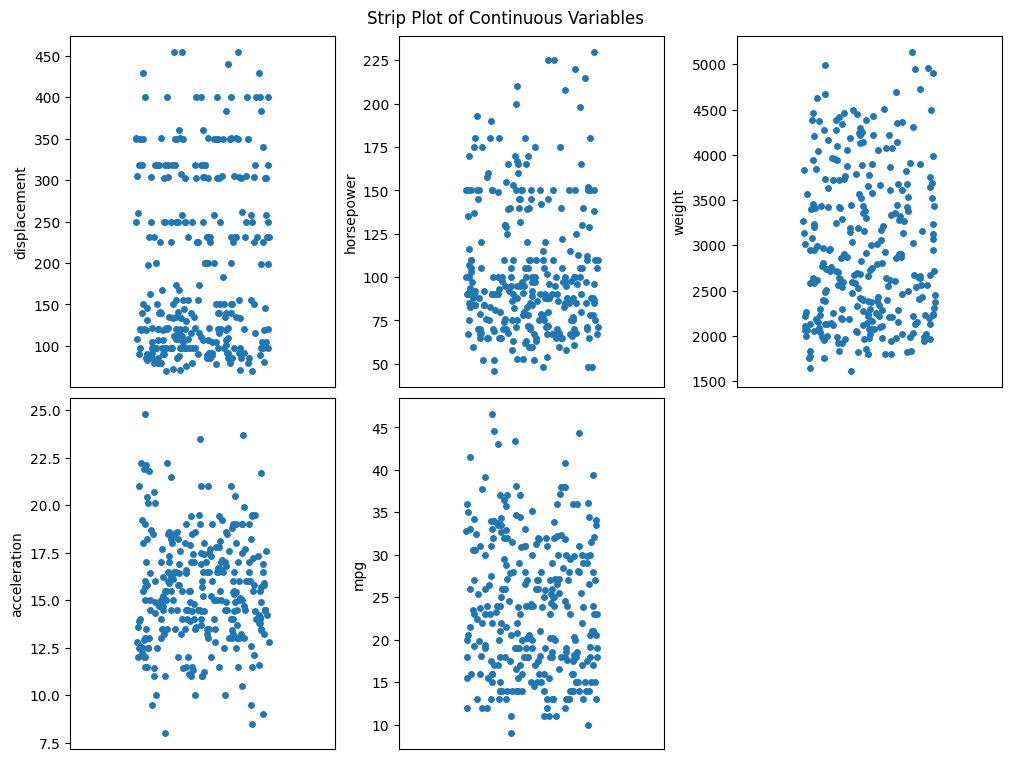

In [18]:
# setup plot figure for continuous variables visualization
width, height = 10, 7.5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Strip Plot of Continuous Variables")

# subset variables with continuous data type from numerical variables
discrete_columns = ["cylinders", "model_year"]
continuous_train = numerical_train.drop(columns=discrete_columns)

# plot visualization for continuous variables
start_enumerate = 1
nrows, ncols = 2, 3
jitter = 0.25
for count, column in enumerate(continuous_train, start_enumerate):
    plt.subplot(nrows, ncols, count)
    sns.stripplot(continuous_train, y=column, jitter=jitter)
    plt.xticks([])

*[Strip plot](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial) is used to show data points across the continuous numerical variables in the Auto MPG dataset.*
* *Each dot represents an observation of a car sample in the Auto MPG dataset.*
* *Because the number of observations is in the hundreds and relatively high, a `jitter` value is applied to display the data points as non-overlapping as possible.*

Several insights can be drawn from this simple visualization, such as the data spread, skewness, and distribution gaps. However, the focus of this analysis is to detect the presence of [outliers](https://en.wikipedia.org/wiki/Outlier) in each variable:
* One can see clusters of data points, such as in the `displacement & horsepower` variables, indicating [modality](https://en.wikipedia.org/wiki/Mode_(statistics)) of continuous values within the range along the $y$-axis that forms these clusters.
* For example, in the `horsepower` variable, there are data points at the upper extremity of the plot representing the value `max (230)` for that variable, which was found earlier and lies relatively far from the mode of the variable.
* It is important to note that this extreme value is not far from the surrounding data points and is not an error as discussed in [Initial Data Inspection](#initial-data-inspection), so it can be defined as a *non-outlier*.

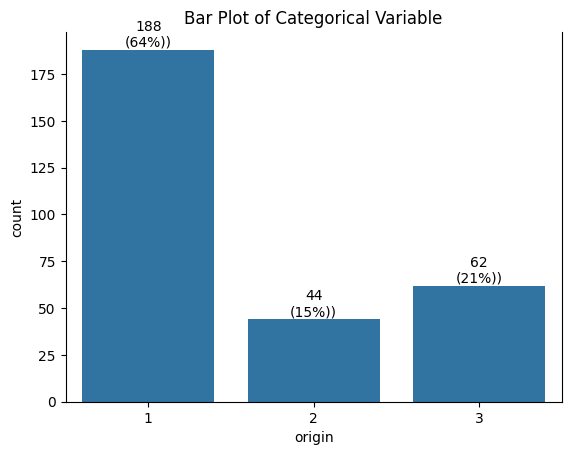

In [19]:
# plot visualization for categorical variables
categorical_column = ["origin"]
multiply_percent = 100
columns = 1
data_barplot = pd.concat([
    data_train[categorical_column].value_counts().sort_index(),
    data_train[categorical_column].value_counts(normalize=True).mul(multiply_percent)
], axis=columns)
axes = sns.barplot(data_barplot.reset_index(), x="origin", y="count")

proportion_index, barplot_index = 1, 0
labels = [
    f"{round(value.get_height())}\n({round(data_barplot.iloc[index, proportion_index])}%))"
    for index, value in enumerate(axes.containers[barplot_index])
]
axes.bar_label(axes.containers[barplot_index], labels=labels)
axes.spines.top.set_visible(False)

plt.title("Bar Plot of Categorical Variable")
plt.show()

*[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) is a chart that presents categorical data with rectangular bars whose heights or lengths are proportional to the values they represent.*
* *One axis of the chart shows the specific categories being compared, and the other axis represents a measured value.*
* *Categorical variables are those whose values are selected from a group of categories—also called labels.*
* *Each chart in the plot above represents the labels in a particular variable and the occurrences (count) of each label.*
* *For example, in the `origin` variable, the label with the highest occurrence is `1`, with `183` observations or `62%` of the entire dataset.*

Based on this visualization, no particular issue is detected with the only categorical feature in the Auto MPG dataset.
* The `origin` variable contains only 3 labels, which is a relatively small number of categories.
* Although label `1` dominates this variable with `64%` of the frequency, labels `2` and `3` are also quite common, covering `15%` and `21%` of the data, respectively.

### Multivariate EDA

*[Multivariate analysis](https://en.wikipedia.org/wiki/Multivariate_statistics) encompasses the simultaneous observation and analysis of more than one variables, in order to understand the relationships between them and their relevance to the problem being studied. It may also determine to what extent it becomes easier to know and predict a value for one variable (possibly a dependent variable) if the value of the other variable (possibly the independent variable) is known.*

#### Discrete-Dependent Relationship

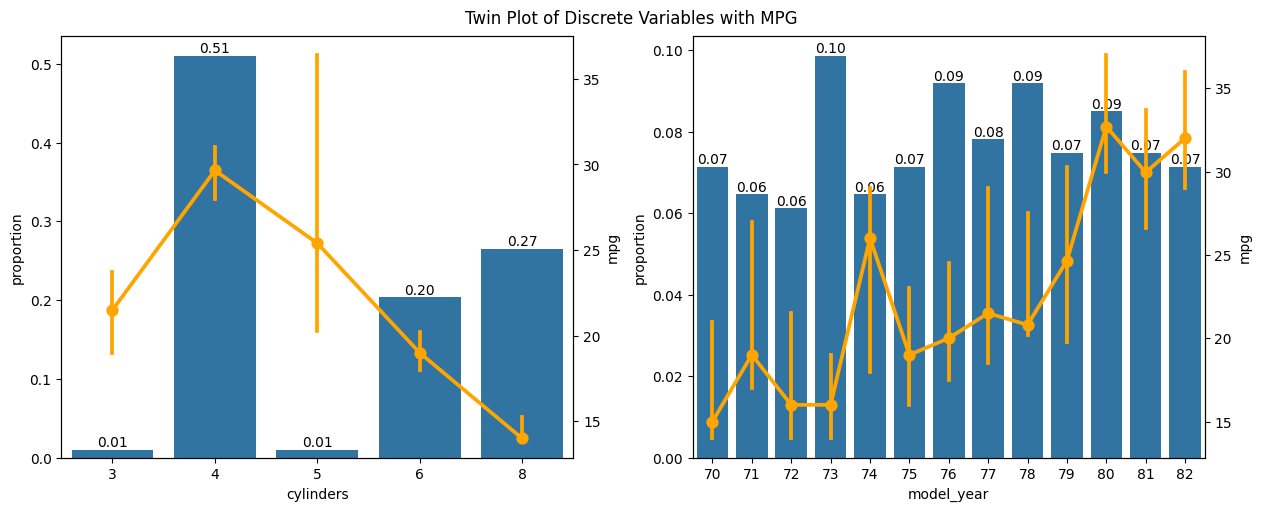

In [20]:
# setup plot figure for discrete variables visualization
width, height = 12.5, 5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Twin Plot of Discrete Variables with MPG")

# subset variables with discrete data type from numerical variables
dependent_column = "mpg"
continuous_columns = continuous_train.drop(columns=dependent_column).columns.tolist()
discrete_dependent_train = numerical_train.drop(columns=continuous_columns)

# plot visualization for discrete variables
nrows, ncols = 1, 2
for count, column in enumerate(discrete_dependent_train, start=start_enumerate):
    if column != dependent_column:
        plt.subplot(nrows, ncols, count)
        kwargs = {"data": discrete_dependent_train, "x": column}

        axes = sns.countplot(**kwargs, stat="proportion")
        axes.bar_label(axes.containers[0], fmt='%.2f')

        axes_twinx = axes.twinx()
        sns.pointplot(
            **kwargs,
            y=dependent_column,
            estimator="median",
            errorbar="ci",
            seed=rng,
            color="orange",
            ax=axes_twinx,
        )

The visualization above consists of 2 components:
1. [Count plot](https://seaborn.pydata.org/generated/seaborn.countplot.html) shows the counts of observations for each discrete value using bars.
    * Instead of counts, `proportion` is used to show the percentages of labels in `cylinders` and `model_year`.
    * The proportion of labels in `model_year` is comparable—ranging from `0.06` or 6% up to 10%.
    * The same cannot be said for `cylinders`: city-cycles with `4` cylinders represent 51% of the whole Auto MPG dataset, while `3 & 5` are **rarely observed**, with only 1% for each of them.
2. [Point plot](https://seaborn.pydata.org/generated/seaborn.pointplot.html) represents an estimate of central tendency for the discrete numerical variables by the position of the dot and provides some indication of the uncertainty around that estimate using [error bars](https://seaborn.pydata.org/tutorial/error_bars.html).
    * *The central tendencies for both variables are also defined according to insights found in [Section 2: Statistical Analysis](#statistical-analysis).*
    * *The confidence interval `ci` is implemented to show the range of likely values for the true population parameter (`median`) over random samples in Auto MPG.*
    * Median MPG shows an overall upward trend in `model_year`, although not perfectly linear. Subsequent analysis performed to check whether a similar pattern occurs in other variables.
    * On the contrary, the median generally decreases as cylinder count increases from `4-8`. The exception is for `3 & 5` cylinders: these cars have a very small sample size, resulting in unstable estimates (wider `mpg` interval).

For values that are over-represented in the dataset, they tend to dominate the outcome. More specifically:
* A number of infrequent values adds noise with little information and therefore causes overfitting.
    * Replacing those labels with either the most frequent value or merging rare values together may be done. However, ideally, the distribution of values within the rare and frequent categories should be evaluated beforehand.
    * Although the proportions of the `3 & 5` values are similar, a significant difference can be seen in the `mpg` interval range for these two values, especially when compared with the frequent value of `4` cylinders.
* Rare values may be present in the training set but not in the test set, which also causes overfitting to the training set.
    * Conversely, rare values may only appear in the test set, so the machine learning model will not know how to evaluate them.

***Addendum: Rare Values Treatment***

In [21]:
class DropValues(BaseEstimator, TransformerMixin):
    """DropValues class for removing specified values from a given column in a DataFrame.
    
    This transformer is designed to be used with scikit-learn's pipeline 
    and allows for the removal of rows in a DataFrame where the specified column contains certain values.
    
    Attributes:
        column (str): The name of the column from which to drop values.
        values (list): A list of values to be removed from the specified column.
    
    Methods:
        fit(X, y=None):
            Fits the transformer to the data. This method is a no-op for this transformer.
    
        transform(X):
            Removes rows from the DataFrame where the specified column contains any of the values to be dropped.
    
    Args:
        column (str): The name of the column to process.
        values (str or list): The value(s) to drop from the specified column. Can be a single value or a list of values.
    """
    def __init__(self, column, values):
        self.column = column
        self.values = values if isinstance(values, list) else [values]

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        mask = ~X[self.column].isin(self.values)
        return X.loc[mask]

To address the issue of noisy rare values of `3 & 5` in the `cylinders` variable, the custom `DropValues` transformer class is used, and those rare values are excluded from the modeling stage that follows.

In [22]:
# discard rare values from "cylinders" column in dataset
rare_column, rare_values = "cylinders", [3, 5]
dropper = DropValues(rare_column, rare_values)
data_cleaned = pd.DataFrame(dropper.fit_transform(data_cleaned))

rare_counts = data_cleaned[rare_column].value_counts()
pd.DataFrame(rare_counts)

,count
cylinders,
4,199
8,103
6,83


* The table above shows the unique labels and counts in `cylinders` after removing the rare values from the variable.
* Another train-test split is then performed to prepare the dataset for feature engineering.

In [23]:
# repeat split after discarding rare values
data_train, data_test = train_test_split(data_cleaned, random_state=rng)

#### Correlation Analysis

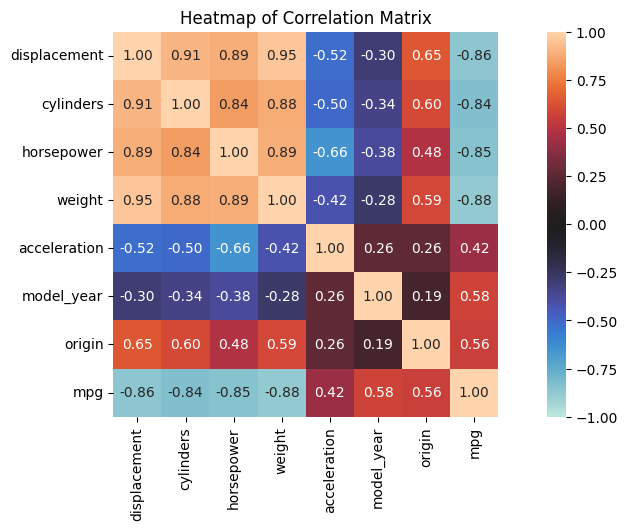

In [24]:
# calculate & visualize correlation of variables
associations_result = associations(
    data_train,
    num_num_assoc="spearman",
    nom_num_assoc="correlation_ratio",
    figsize=(width, height),
    title="Heatmap of Correlation Matrix"
)

associations_result["ax"]
plt.show()

*The heatmap above is a visualization of the pairwise [correlation matrix](https://en.wikipedia.org/wiki/Correlation#Correlation_matrices) between features in `data_train`, using:*
* *[Spearman's R](https://en.wikipedia.org/wiki/Spearman's_rank_correlation_coefficient) to measure monotonicity between numerical variables, and*
* *[Correlation ratio](https://en.wikipedia.org/wiki/Correlation_ratio) to assess the linear/curvilinear relationship between nominal (categorical) and numerical variables.*

In general, the key point here is the cluster of near-perfect positive coefficients in the upper left of the plot, from `displacement` to `weight` across both axes.
* This means that all data points with larger $x$-axis values than a given point will also tend to have larger $y$-axis values, and vice versa.
* Additional information is provided through the [Variance Inflation Factor](#linear-model-assumption) analysis below to assess correlations beyond pairwise relationships (multivariate).

#### Linear Model Assumptions

In [25]:
# setup design matrices for statsmodels
formula = "mpg ~ displacement + cylinders + horsepower + weight + acceleration + model_year + C(origin)" # treat "origin" explicitly as categorical
endog, exog = patsy.dmatrices(formula, data_train, return_type="dataframe")

# fit ordinary least squares (OLS) model
model = sm.OLS(endog, exog)
results = model.fit()

# access attributes from fitting results
y_pred = results.fittedvalues
resid = results.resid
influence = results.get_influence()
resid_norm = influence.resid_studentized_internal
resid_norm_abs_sqrt = np.sqrt(np.abs(resid_norm))
leverage = influence.hat_matrix_diag

*A linear model serves as one of the simplest, most interpretable, and strongest baseline methods for statistical learning (James, 2023, pp. 23-5).*
* *Although in reality the relationships between variables are often not linear, fitting a linear regression to a nonlinear relationship in this case may be problematic.*
* *The following section uses the output from `statsmodels` to visualize and identify potential problems that may arise from fitting a linear model to the dataset when doing so violates the [assumptions of linear regression](https://en.wikipedia.org/wiki/Ordinary_least_squares#Assumptions).*

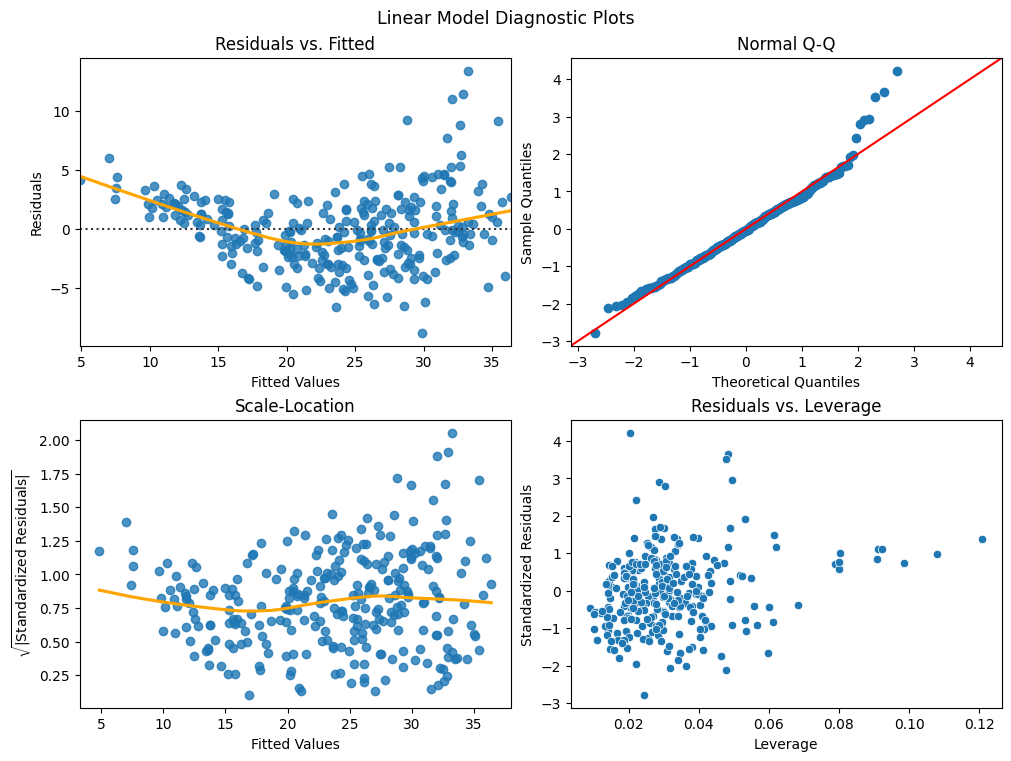

In [26]:
# visualize diagnostics for linear model assumptions
width, height = 10, 7.5
fig = plt.figure(figsize=(width, height), layout="constrained")
mosaic = [
    ["residuals", "qqplot"],
    ["scale_location", "influence"]
]
axes = fig.subplot_mosaic(mosaic)

ax = sns.residplot(
    x=y_pred,
    y=resid,
    lowess=True, # smooth fit to the residuals for easier identification of trends
    line_kws={"color": "orange"},
    ax=axes["residuals"],
)
ax.set_title("Residuals vs. Fitted")
ax.set_xlabel("Fitted Values")
ax.set_ylabel("Residuals")

sm.qqplot(resid_norm, line="45", ax=axes["qqplot"])
axes["qqplot"].set_title("Normal Q-Q")

ax = sns.regplot(
    x=y_pred,
    y=resid_norm_abs_sqrt,
    lowess=True,
    line_kws={"color": "orange"},
    ax=axes["scale_location"]
)
ax.set_title("Scale-Location")
ax.set_xlabel("Fitted Values")
ax.set_ylabel("$\\sqrt{|\\text{Standardized Residuals}|}$", fontsize=10)

ax = sns.scatterplot(
    x=leverage,
    y=resid_norm,
    ax=axes["influence"],
)
ax.set_title("Residuals vs. Leverage")
ax.set_xlabel("Leverage")
ax.set_ylabel("Standardized Residuals")

plt.suptitle("Linear Model Diagnostic Plots", fontsize=12.5)
plt.show()

1. Residual vs. Fitted plot is a useful tool for identifying [linear combination](https://en.wikipedia.org/wiki/Linear_combination) of the regression parameters resulting in mean values of the response variable.
    * *Given a linear regression model consisting of multiple variables, residuals are plotted using the formula of $e^i = y^i − \hat{y}^i$ versus predicted (fitted) values $y^i$.*
    * *Ideally, data points in the plot will show no discernible pattern. The presence of a pattern may indicate a problem with some aspect of the linear model.*
    * From the panel, the residuals exhibit a clear U-shape, which provides a strong indication of non-linearity in the data.
    * If the true relationship is far from linear, then virtually all of the conclusions drawn from the fit are suspect. In addition, the prediction accuracy of the model can be significantly reduced.
2. Normal [Q-Q plot](https://en.wikipedia.org/wiki/Q%E2%80%93Q_plot) is used to visually check if residuals are normally distributed. 
    * *[Statistical population](https://en.wikipedia.org/wiki/Statistical_population) is plotted on the $x$-axis and compared with sample data ([internally studentized residual](htthttps://en.wikipedia.org/wiki/Studentized_residual#Internal_and_external_studentization) from the model) on the $y$-axis; both as their quantiles against each other.*
    * *If the two distributions being compared are similar, the points in the plot will approximately lie on the identity line $y = x$.*
    * Although data points roughly on quantiles `-2` up to `2` lie on the diagonal line, the endpoints are dispersed, with heavy tail observed on the larger quantiles.
    * Under the normality assumption, OLS aligns with [maximum likelihood estimation](https://en.wikipedia.org/wiki/Maximum_likelihood_estimation) as the objective function is to minimize squared error.
3. Scale-Location plot is a regression diagnostic chart used to check homogeneity of variance a.k.a. [homoscedasticity](https://en.wikipedia.org/wiki/Homoscedasticity_and_heteroscedasticity).
    * *`Scale` refers to scaled [studentized residuals](https://en.wikipedia.org/wiki/Studentized_residual)—taking square root of the absolute value—, hereby focusing on the normalized magnitude of the residuals. While `Location` represents where the prediction sits for each data point.*
    * *For the data to conform with the assumption, the red smoothed trend line is roughly horizontal (flat) across the graph, and the data points are randomly and evenly scattered with consistent vertical spread from left to right.*
    * On the contrary, the red line curves (albeit slightly) along the fitted values, and the points form a distinct funnel or fan shape (widening across the $x$-axis).
    * Non-constant variance leads to less precise parameter estimates and biased standard errors, resulting in misleading statistical tests and interval estimates.
4. Residuals vs. [Leverage](https://en.wikipedia.org/wiki/Leverage_(statistics)) plot visualizes observations for which the value may be unusual given certain predictor and/or response variables.
    * *Instances with high standardized residual values are deemed outliers—for which $y^i$ is far from the value predicted by the model—, while data points with high leverage statistic have an abnormal value for $x^i$.*
        * *Outliers can arise for a variety of reasons, such as incorrect recording of an observation during data collection.*
        * *In a multiple regression setting with many predictors, it is possible to have an instance that is well within the range of each individual predictor’s values, but that is unusual in terms of the full set of predictors.*
    * Visually, data points with leverage value around `0.08` and above are deemed unusual when compared against the rest; the same may not be applicable for the single observation with `4` standardized residual value since it is located quite near the instances with residuals around `3.5`.
    * Certain fitted model would likely pass close to high leverage observations, hence having the potential to cause large changes (increase sensitivity) in the parameter estimates when they are deleted—i.e., to be [influential points](https://en.wikipedia.org/wiki/Influential_point)—for the same residual size.
5. [Variance Inflation Factor](https://en.wikipedia.org/wiki/Variance_inflation_factor) (VIF) table (*shown below*) measures [multicollinearity](https://en.wikipedia.org/wiki/Multicollinearity) or linear dependency between predictors in a regression model.
    * *VIF is the ratio of the variance of coefficient estimates $\beta^i$ when fitting the full model divided by the variance of $\beta^i$ if fitted on its own.*
    * *As a rule of thumb, a VIF value that exceeds 5 or 10 indicates a problematic amount of multicollinearity.*
    * In Auto MPG dataset, a regression of `mpg` on the predictor variables indicates that several variables have VIF values above the common thresholds and abnormally valued above other variables; ranging from `10.30` (`cylinders`) up to `24.06` (displacement).
    * The presence of multicollinearity can be problematic, since it can be difficult to separate out the individual effects of the variables on the outcome.
        * In other words, since `cylinders`, `horsepower`, `weight`, and `displacement` tend to increase or decrease together, it can be difficult to determine how each one separately is associated with the response `mpg`.
        * Multicollinearity also reduces the accuracy of the estimates of the regression coefficients, causing the standard error for $\beta^i$ to grow and further reducing the power of hypothesis test (the probability of correctly detecting a non-zero coefficient).
        * This is also relevant to machine learning methods that use the [permutation](https://scikit-learn.org/stable/modules/permutation_importance.html) technique. For example, permuting input variables to measure their importance can produce unlikely data instances when those variables are correlated, thereby reducing—or even biasing—the importance value.

In [27]:
# measure VIF of exogeneous variables in the model
shape_column = 1
decimal_places = 2
df_vif = pd.DataFrame({
    "VIF": [
        variance_inflation_factor(pd.DataFrame(exog).values, i)
        for i in range(exog.shape[shape_column])
    ],
}, index=pd.DataFrame(exog).columns)
df_vif.sort_values("VIF").round(decimal_places)

,VIF
model_year,1.30
C(origin)[T.2],1.68
C(origin)[T.3],1.70
acceleration,2.75
cylinders,10.30
horsepower,10.33
weight,13.98
displacement,24.06
Intercept,788.01


### Analysis Summary

| Anomaly | Description & Solution |
| --- | --- |
| Variable Magnitude | A difference in magnitude was detected across the numerical variables |
| Rare Values | `3 & 5` values were identified as having a much lower proportion than other values in the `cylinders` variable and handled accordingly |
| Linear Model Assumptions | Diagnostic plots and tables show that the Auto MPG dataset does not conform to a linear model |
| Objective Function | Violations of normality may lead to inaccurate predictions when squared error is used as a [point estimate](https://en.wikipedia.org/wiki/Point_estimation) for skewed distribution of `mpg` |
| Multicollinearity | VIF values above common thresholds identified in `cylinders, horsepower, weight, & displacement` |

---

## Section 3 | Predictive Modeling

In [28]:
# import required libraries
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import PredictionErrorDisplay, median_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    LearningCurveDisplay,
    cross_validate,
)
from sklearn.pipeline import make_pipeline

### Modeling Pipeline

*To build a composite estimator, transformers are usually combined with other transformers or with predictors. There is often a fixed sequence of steps in processing the data—in this case, the examples are data ETL, cleaning inconsistencies, input splitting, and estimating output values.*

In [29]:
def feature_target_split(dataset, random_state, column_target="mpg"):
    """Splits a dataset into features and target variables for training and testing.
    
    Args:
        dataset (pd.DataFrame or similar): The input dataset containing features and the target variable.
        random_state (int): The seed used by the random number generator for reproducibility.
        column_target (str, optional): The name of the target variable column. Defaults to "mpg".
    
    Returns:
        tuple: A tuple containing:
            - X_train (pd.DataFrame): The training set features.
            - X_test (pd.DataFrame): The testing set features.
            - y_train (pd.Series): The training set target variable.
            - y_test (pd.Series): The testing set target variable.
    """
    X = pd.DataFrame(dataset).drop(columns=column_target)
    y = pd.Series(dataset[column_target])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=random_state)

    return X_train, X_test, y_train, y_test

*In machine learning:*
* *Features are the input variables (independent variables) used to make predictions, while*
* *The target is the variable to be predicted or understood (dependent variable).*
* *Together, they form the basis for supervised learning, where features map to a target value. Features are selected for relevance, and the target is the goal.*

In [30]:
# split features and target to random train and test subsets
X_train, X_test, y_train, y_test = feature_target_split(data_cleaned, rng)

# perform dimensionality analysis of train-test subsets
inspect_dimensionality(data_cleaned, X_train, X_test)

,row_n,row_ratio,column
dataset,385,1.000000,8
train,288,0.748052,7
test,97,0.251948,7


The split process above is roughly similar to the one performed in [Section 2: Train-Test Split](#train-test-split), with a few differences:
* `feature_target_split` divides `data` into 2 pairs: `X_train - X_test` and `y_train - y_test`.
* The overall data split proportion remains the same, but because the target variable `mpg` is also separated into `y_train` and `y_test`, the number of columns in `train` and `test`—that is, `X_train` and `X_test`—is reduced by 1 variable.

This function is integrated together with the preprocessors defined earlier into the following [pipeline](https://scikit-learn.org/stable/modules/compose.html) building process:

In [31]:
def modeling_pipeline(
    id,
    random_state,
    max_depth,
    l2_regularization,
    max_features,
    scoring
):
    """Modeling pipeline for data preprocessing and regression model training.
    
    This function creates a modeling pipeline that includes data preprocessing steps and a regression model. It performs the following tasks:
    1. Matches categories in the dataset.
    2. Drops specified rare values from the dataset.
    3. Cleans the data using the defined preprocessing steps.
    4. Splits the cleaned data into training and testing features and targets.
    5. Initializes a HistGradientBoostingRegressor with specified hyperparameters.
    6. Returns the preprocessing pipeline and the dataset split.
    
    Args:
        id (int): Identifier for the dataset to be processed.
        random_state (int): Seed for random number generation to ensure reproducibility.
        max_depth (int): Maximum depth of the regression model.
        l2_regularization (float): L2 regularization parameter for the regression model.
        max_features (int): Maximum number of features to consider when looking for the best split.
        scoring (str): Scoring method to evaluate the model during training.
    
    Returns:
        tuple: A tuple containing:
            - dict: A dictionary with the preprocessing pipeline and the regression estimator.
            - dict: A dictionary containing the training and testing datasets, each as a tuple of features and targets.
    """
    match = MatchCategories(invalid_column, ignore_format=True)
    drop_values = DropValues(rare_column, rare_values)
    preprocessing_pipeline = make_pipeline(match, drop_values)

    data = data_etl(id)
    data_cleaned = preprocessing_pipeline.fit_transform(data)
    train_features, test_features, train_target, test_target = feature_target_split(data_cleaned, random_state)

    regressor = HistGradientBoostingRegressor(
        loss="absolute_error",
        max_depth=max_depth,
        l2_regularization=l2_regularization,
        max_features=max_features,
        early_stopping=True,
        scoring=scoring,
        random_state=rng
    )

    pipeline = {
        "preprocessing": preprocessing_pipeline,
        "estimator": regressor
    }
    dataset = {
        "train": (train_features, train_target),
        "test": (test_features, test_target)
    }

    return pipeline, dataset

This model, [`HistGradientBoostingRegressor`](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), was selected based on the following considerations:
* As a new implementation of [Gradient-boosted Trees](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting)—which combine the predictions of several decision trees as their base estimators—, this particular model requires [little](https://scikit-learn.org/stable/modules/tree.html) data preparation:
    * It bypasses the need for data normalization by considering that decision trees use monotonic, [if-then-else](https://scikit-learn.org/stable/modules/tree.html) threshold rules to build the model.
    * `HistGradientBoostingRegressor` has [native support for categorical features](https://scikit-learn.org/stable/modules/ensemble.html#categorical-features-support), which is often better than relying on one-hot and/or ordinal encoding commonly used to convert such features into numerical representations for machine learning models.
    * This model also has [built-in support for missing values](https://scikit-learn.org/stable/modules/ensemble.html#missing-values-support), further reducing preprocessing complexity as shown in the display below.
* More importantly, this [non-parametric model](https://en.wikipedia.org/wiki/Nonparametric_statistics#Nonparametric_models) does not specify or assume the functional form of the model a priori—as was done in [Section 2: Linear Model Assumptions](#linear-model-assumptions)—but instead seeks an estimate as close as possible to the observed data points.

After the appropriate model is selected, the next step is to set the configurable [hyperparameters](https://en.wikipedia.org/wiki/Hyperparameter_(machine_learning)) inside the model:
* For the purpose of [selecting an appropriate loss function](https://en.wikipedia.org/wiki/Loss_function#Selecting_a_loss_function), a robust statistical method—in which the loss parameter is specified as [`absolute_error`](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting-loss)—is implemented to produce statistical results that are not unduly affected by heavy-tailed distributions as demonstrated in [Section 2: Linear Model Assumptions](#linear-model-assumptions).
* [Early stopping](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_early_stopping.html) is a technique in gradient boosting to find the optimal number of iterations (`max_iter` in `HistGradientBoostingRegressor`) required to build a model that generalizes well to unseen data and avoids [overfitting](https://en.wikipedia.org/wiki/Overfitting).
    * *Enabling `early_stopping` also requires the `scoring` parameter to be set. The initial model is given by the [median](https://scikit-learn.org/stable/modules/ensemble.html#loss-functions) of the target values, hence the corresponding `neg_median_absolute_error` scoring string name is used.*
    * *The scoring object follows the [convention](https://scikit-learn.org/stable/modules/model_evaluation.html#string-name-scorers) that higher return values are better than lower return values. Thus the metric is available with the `neg_` prefix, which returns negated values of the error.*
* As for the tunable hyperparameters, namely `learning_rate`, `max_depth`, and `min_samples_leaf`, the values of these parameters use the default values first (*implemented below*) before being optimized in the next section.

In [32]:
# define tunable hyperparameters for modeling pipeline
max_depth = None
l2_regularization = 0
max_features = 1
scoring = "neg_median_absolute_error"

# execute modeling pipeline
pipeline, dataset = modeling_pipeline(
    id_auto_mpg,
    rng,
    max_depth,
    l2_regularization,
    max_features,
    scoring
)

# display preprocessing pipeline and trained estimator
print("Preprocessing Pipeline:")
display(pipeline["preprocessing"])
print("Trained Estimator:")
display(pipeline["estimator"])

Preprocessing Pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('matchcategories', ...), ('dropvalues', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variables,'origin'
,ignore_format,True
,missing_values,'raise'
,column,'cylinders'
,values,"[3, 5]"


Trained Estimator:


,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'absolute_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4

| Anomaly | Solution |
| --- | --- |
| Variable Magnitude | Implementing `HistGradientBoostingRegressor` as a scale-invariant model does not necessitate normalization of each input variables |
| Linear Model Assumptions | Gradient-boosted algorithm avoids the assumption of any particular functional form of the parameters/features |
| Objective Function | A [strictly consistent scoring function](https://en.wikipedia.org/wiki/Scoring_rule) which measures the absolute midpoint value is chosen as loss function and as metric/scoring |

### Hyperparameter Tuning

*[Hyperparameter tuning](https://en.wikipedia.org/wiki/Hyperparameter_optimization) determines the set of hyperparameters that yields an optimal model which minimizes a predefined loss function on a given data set. The objective function takes a set of hyperparameters and returns the associated loss.*

In [33]:
# setup hyperparameter grid space
param_name_max_depth = "max_depth"
start, stop, step = 1, 4, 1
param_range_max_depth = range(start, stop, step)

param_name_l2_regularization = "l2_regularization"
start, stop, num = -1, -3, 3
holdout_param = np.logspace(start, stop, num)
insert_index = 0
param_range_l2_regularization = np.insert(holdout_param, insert_index, l2_regularization) # include default value in the gridspace

param_name_max_features = "max_features"
X_train, y_train = dataset["train"]
start, stop, step, ndigits = len(X_train.columns), 0, -2, 3
param_range_max_features = [round(max_features / divisor, ndigits) for divisor in range(start, stop, step)]

param_grid = {
    param_name_max_depth: param_range_max_depth,
    param_name_l2_regularization: param_range_l2_regularization,
    param_name_max_features: param_range_max_features
}

*The traditional method for hyperparameter optimization has been [grid search](https://en.wikipedia.org/wiki/Hyperparameter_optimization#Grid_search):*
* *Which is simply an exhaustive searching through a manually specified subset of the hyperparameter space of a learning algorithm.*
* *Since the parameter space of a machine learner may include real-valued or unbounded value spaces for certain parameters, manually set bounds and discretization may be necessary before applying grid search.*

The most important hyperparameters for gradient-boosted trees, along with an explanation of the selected grid space, are as follows:
1. The number of $d$ splits in each tree, which controls the complexity of the boosted ensemble.
    * More generally, $d$ is the interaction `depth`, and controls the interaction order of the boosted model, since certain splits can involve at most $d$ variables.
    * Therefore, the value of $d$ is restricted from 1 (representing [decision stumps](https://en.wikipedia.org/wiki/Decision_stump), where no interaction between variables is allowed) up to 3 (the model may include effects of interactions among up to $2^3$ variables), considering the main principle of weak learners—building shallow trees sequentially to correct the errors of previous ones—used by `HistGradientBoostingRegressor`.
2. [`l2_regularization` in Gradient Boosting](https://scikit-learn.org/stable/modules/ensemble.html#details-on-l2-regularization) works by penalizing the magnitude of leaf values (predicted outputs of individual tree leaves) in the ensemble of trees. As with the previous grid space, a logarithmic scale is used for this parameter to cover a wide range of values and avoid bias toward a particular magnitude.
3. Setting `max_features` is analogous to [subsampling](https://scikit-learn.org/stable/modules/ensemble.html#subsampling), in which the base model is trained on a proportion of randomly selected features at each node split.
    * This is a form of regularization: smaller values make the trees weaker learners and may help prevent overfitting.
    * Gridspace dari parameter ini diatur to be evenly spaced within the total number of features in the train set.

In [34]:
# setup cross-validation methods
n_splits_inner, n_splits_outer = 6, 12
kwargs = {"shuffle": True, "random_state": rng}
inner_cv, outer_cv = KFold(n_splits_inner, **kwargs), KFold(n_splits_outer, **kwargs)

*[Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) is related to a methodology in supervised machine learning used to avoid overfitting and data leakage.*
* *Consistent with the information from [Section 1: Data Dictionary](#data-dictionary), the `car_name` column in the Auto MPG dataset functions as a unique identifier for each car instance. It can therefore be approximated that the samples in this dataset are [independent and identically distributed](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators) (i.i.d.).*
* *Thus, cross-validation methods such as K-Fold, Repeated K-Fold, and Shuffle Split can be used as the specific methods for applying the hyperparameter tuning procedure over the defined space to search for the best cross-validation scores.*

The default choice of [`KFold`](https://scikit-learn.org/stable/modules/cross_validation.html#k-fold) and its parameters is used in the following steps.
* This iterator divides all samples into $k$ groups of equal size (if possible), called folds.
* By setting `shuffle=True`, the folds represent mixtures of car observations and improve the reliability of future model evaluation. It is also assumed that the rows in the dataset are ordered arbitrarily and without any meaningful structure.

In [35]:
# perform hyperparameter search over nested cross-validation procedure
n_jobs = -1
search = GridSearchCV(
    pipeline["estimator"],
    param_grid=param_grid,
    scoring=scoring,
    n_jobs=n_jobs,
    cv=inner_cv
)

*Given the limited hyperparameter space defined earlier, [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) can be used to exhaustively search over the specified parameter values for the estimator.*
* *[`n_jobs`](https://scikit-learn.org/stable/glossary.html#term-n_jobs) is set to `-1` to use all processors concurrently and in parallel, thereby accelerating the computation required to search over the parameter space across several cross-validation splits.*
* *For multiple metric evaluation yang telah ditetapkan sebelumnya, `refit` parameter needs to be a string denoting the scorer that would be used to find the best parameters for refitting the estimator at the end —in this case, `neg_medae` as stated beforehand.*

[Nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html#nested-versus-non-nested-cross-validation) is used to further avoid data leakage by separating the folds used in the:
* `inner_cv` loop (executed here by `GridSearchCV`), which approximately optimizes the score by fitting the model to each training set and then selecting hyperparameters over the validation set;
* `outer_cv` loop (implemented via `cross_val_score` afterwards), which estimates the generalization error by averaging test-set scores across different data splits.
* A value of `6` is chosen for the number of splits in `inner_cv`, which corresponds to the number of observations in `X_train` (`288`) as an exact multiple of it—producing folds of equal size—and double the value in `outer_cv` in an attempt to balance the computational cost and representative performance of the model.

Finally, the `search` estimator with the best hyperparameters found by `GridSearchCV` is [fitted](https://scikit-learn.org/stable/glossary.html#term-fit) to the full training set, as implemented below.

In [36]:
# fit model with the best hyperparameters over the train set
search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...solute_error')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'l2_regularization': array([0. ,...0.01 , 0.001]), 'max_depth': range(1, 4), 'max_features': [0.143, 0.2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_median_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the com

### Model Evaluation

*Model evaluation measure how well machine learning models accomplish their intended tasks. Evaluation functions—using different metrics and techniques—quantify performance, reveal weaknesses, and guide improvement.*

#### Evaluation Metric

In [37]:
# hyperparameters grid space
df_params = pd.DataFrame({
    "max_depth": [tuple(param_range_max_depth)],
    "l2_regularization": [param_range_l2_regularization],
    "max_features": [param_range_max_features]
}, index=["grid_params"])

# chosen hyperparameters from inner_cv
df_cv_params = pd.DataFrame(
    [(search.cv_results_["params"][search.best_index_])],
    index=["best_params"]
)

pd.concat([df_params, df_cv_params]).transpose()

,grid_params,best_params
max_depth,"(1, 2, 3)",3
l2_regularization,"[0.0, 0.1, 0.01, 0.001]",0.001
max_features,"[0.143, 0.2, 0.333, 1.0]",0.333


The chosen hyperparameters from the inner `6`-fold cross-validation loop are displayed in the table above.
* The best `max_depth` parameter is `3`—which lies at the upper edge of the grid space—indicating that the space could potentially be extended higher.
* The model chooses to implement regularization by selecting `l2_regularization` to `0.1` instead of the `0.0` default value (no regularization).
* The same can be said for the `max_features` parameter, where the tuned model prefers a typical value of maximum `0.333` or one-third of the total features.

In [38]:
# cross-validated scores from outer_cv
params_cv = {
    "estimator": search.best_estimator_,
    "X": X_train,
    "y": y_train,
    "scoring": scoring,
    "cv": outer_cv,
    "n_jobs": -1,
}
cv_scores = cross_validate(**params_cv)
df_cv = pd.DataFrame({
    "MedAE": [abs(np.mean(cv_scores["test_score"])), np.std(cv_scores["test_score"])],
}, index=["mean", "std"])

# test scores from best estimator fitted on train set
X_test, y_test = dataset["test"]
y_pred = pd.Series(
    search.best_estimator_.predict(X_test),
    index=pd.Series(y_test).index,
    name="mpg_pred"
)
df_pred = pd.DataFrame({
    "MedAE": [median_absolute_error(y_test, y_pred)],
})

multiindex_tuples = [
    ('cv_scores', 'mean'),
    ('cv_scores', 'std'),
    ('test_scores', '')
]
multiindex = pd.MultiIndex.from_tuples(multiindex_tuples)
pd.concat([df_cv, df_pred]).set_index(multiindex)

MedAE
cv_scores   mean  1.359148
            std   0.320987
test_scores       1.593838

After that, the average `mean` and variation `std` computed in the outer cross-validation procedure `(cv_scores)` are displayed.
* *Since the scoring is sign-flipped, the absolute value `abs()` is used to make the average score easier to interpret.*
* *`mean` measures the average value of model's performance over $k$-folds, while `std` represents variance of the performance across different folds.*
* `cv_scores` serve as **a baseline estimate of the model's expected generalization performance**.
* Additionally, `test scores` are included to assess the consistency of the model's performance against the true out-of-sample performance. With scores close to the mean and within the standard deviation of `cv_scores`, it can be inferred that the model generalizes similarly to cross-validation expectations.

#### Early Stopping Curve

In [39]:
# compute errors at each stage of the boosting process
train_errors, test_errors = [], []

for _, (y_pred_train_staged, y_pred_test_staged) in enumerate(
    zip(
        search.best_estimator_.staged_predict(X_train),
        search.best_estimator_.staged_predict(X_test),
    )
):
    train_errors.append(median_absolute_error(y_train, y_pred_train_staged))
    test_errors.append(median_absolute_error(y_test, y_pred_test_staged))

* *Code above calculates the defined loss function for both training and test datasets from the model per boosting iterations.*
* *The purpose is to assess the performance and convergence of the models as elaborated below:*

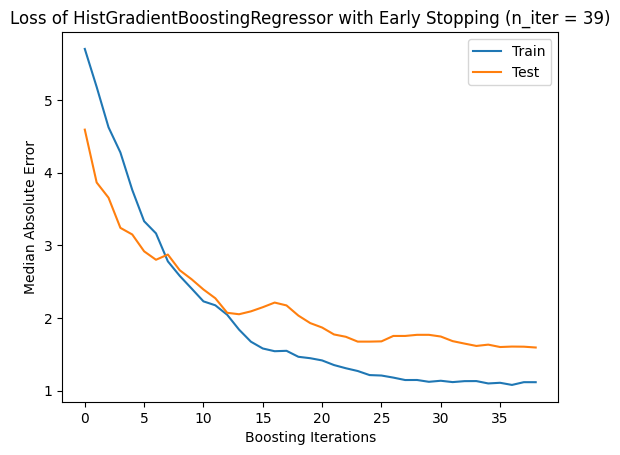

In [40]:
# plot errors with the optimal number of iterations
plt.plot(train_errors, label="Train")
plt.plot(test_errors, label="Test")

regressor_name = pipeline["estimator"].__class__.__name__
scoring_name = "Median Absolute Error"
n_iter_stopped = search.best_estimator_.n_iter_
plt.title(f"Loss of {regressor_name} with Early Stopping (n_iter = {n_iter_stopped})")
plt.xlabel("Boosting Iterations")
plt.ylabel(scoring_name)
plt.legend()
plt.show()

*Early stopping is a technique in Gradient Boosting to find the optimal number of iterations required to build a model that generalizes well, with its steps as follows:*
1. *A portion of the dataset is set aside as an internal validation set (specified using `validation_fraction`) to assess the model’s performance during training.*
2. *As the model is iteratively built with additional stages (trees), its performance on the validation set is monitored as a function of the number of steps.*
3. *Early stopping becomes effective when the model’s performance on the validation set plateaus or worsens (within deviations specified by `tol`) over a certain number of consecutive stages (specified by `n_iter_no_change`).*
4. *This signals that the model has reached a point where further iterations may lead to overfitting, and it is time to stop.*

* *Aforementioned parameters are automatically specified by scikit-learn and used in this section for efficiency purposes.*
* *The lines appear jagged, likely because the median absolute error is used to evaluate the loss: the median of the losses can remain unchanged and then jump suddenly when predictions cross the middle-ranked errors.*

Initially, early stopping is applied on `Train` set (blue line) to find the optimal `n_iter`, in which the model's error apparently plateaus after `61` iterations.
* With the same number of `n_iter`, staged prediction is implemented on `Test` set (green line).
* The gap between both lines is relatively low (`~0.5`), which indicates that model is **learning well and generalizing reasonably**.

#### Learning Curve

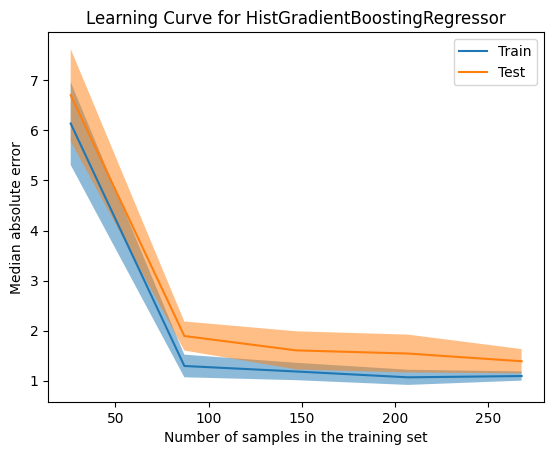

In [41]:
# visualize learning curve of the best estimator fitted on train set
display = LearningCurveDisplay.from_estimator(
    **params_cv,
    shuffle=True,
    random_state=rng,
    negate_score=True
)

plt.title(f"Learning Curve for {regressor_name}")
plt.show()

*[Learning curve](https://scikit-learn.org/stable/modules/learning_curve.html#learning-curve) shows the training and validation score of an estimator for varying numbers of training samples.*
* *It is a tool to find out how much benefit obtained from adding more training data, and whether the estimator suffers more from [bias or variance]((https://en.wikipedia.org/wiki/Bias%E2%80%93variance_tradeoff)) error.*
* *The curves are plotted from averages of cross-validation scores fitted on `X_train & y_train`:*
    * *Therefore, the `Test` label is actually the internal validation set from the training set, rather than the separate `Test` set used in this project (`X_test, y_test`).*
    * *And the variability is shown with the shaded areas that represent a standard deviation above and below the mean for all cross-validations.*
    * *`negate_score` parameter is set to `True` which corresponds with previous implementation in [Section 3: Evaluation Metrics](#evaluation-metrics)*.

The observed pattern can be interpreted as follows:
* With small training samples `<50`, both training and test errors are much higher and slightly more variable (a.k.a. *variance error*), which comes from insufficient data that underfits the model and making it *sensitive to limited data*.
* As the training set increases around `<100` observations, the errors decrease steadily, implying that **generalization improves from adding more training data**.
* After roughly `150` training samples, both curves flatten and remain close to one another.
    * This convergence suggests that adding more samples or any additional trainings from Auto MPG dataset are unlikely to produce further reduction in error.
    * The plot also corresponds with previous early stopping visualization: the model needs more data to reduce error and improve prediction.

#### Prediction Error

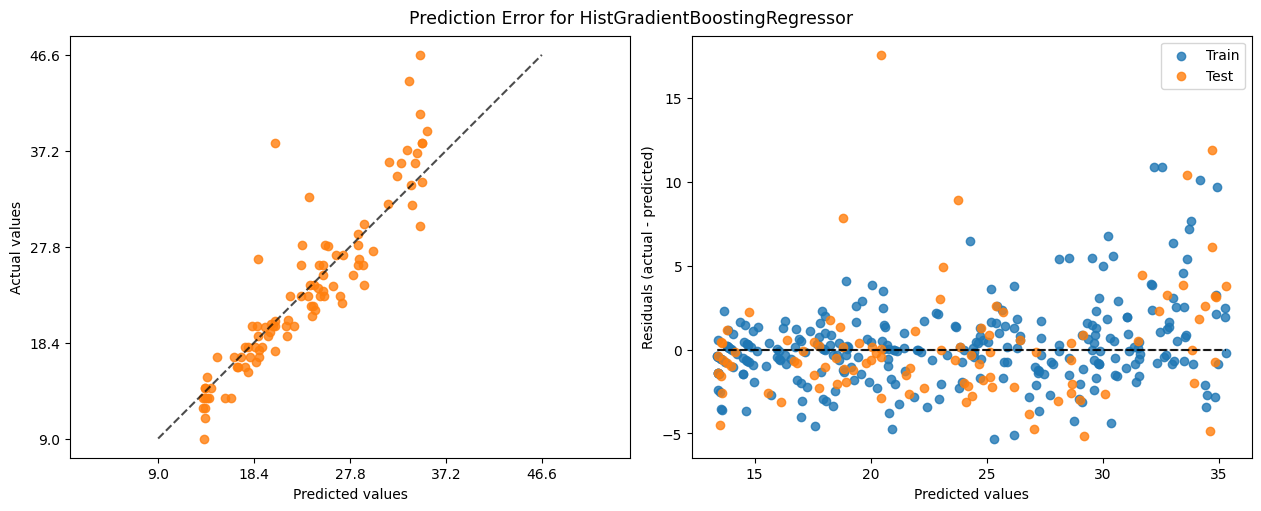

In [42]:
# plot prediction error given the true and predicted targets
width, height = 12.5, 5
fig = plt.figure(figsize=(width, height), layout="constrained")
mosaic = [["actual_vs_predicted", "residual_vs_predicted"]]
axes = fig.subplot_mosaic(mosaic)

color_spec = "C1" # use second-index default color spec for consistency purpose
PredictionErrorDisplay.from_predictions(
    y_test,
    y_pred,
    kind="actual_vs_predicted",
    ax=axes["actual_vs_predicted"],
    scatter_kwargs={"color": color_spec}
)

y_pred_train = pd.Series(
    search.best_estimator_.predict(X_train),
    index=pd.Series(X_train.index),
)
PredictionErrorDisplay.from_predictions(
    y_train,
    y_pred_train,
    kind="residual_vs_predicted",
    ax=axes["residual_vs_predicted"],
    scatter_kwargs={"label": "Train"},
)
PredictionErrorDisplay.from_predictions(
    y_test,
    y_pred,
    kind="residual_vs_predicted",
    ax=axes["residual_vs_predicted"],
    scatter_kwargs={"color": color_spec, "label": "Test"}
)

plt.suptitle(f"Prediction Error for {regressor_name}", fontsize=12.5)
plt.legend()
plt.show()

The figure above consists of two parts:

*1. [Prediction error](https://scikit-learn.org/stable/modules/model_evaluation.html#visual-evaluation-of-regression-models) plot on the left shows the actual $`y`$ targets from the dataset against the predicted $\hat{y}$ values generated by the model.*
* *This allows the user to see where the error is occurring, in what magnitude, and how much variance is present.*
* *The dotted lines in both plots indicate zero error, where the prediction exactly matches the observed value.*
* For a noise-free regression task aiming to predict the (conditional) expectation of $y$, a perfect regression model would display data points on the diagonal defined by predicted values equal to actual values.
    * In a more realistic setting with irreducible noise, that is, when not all variations of $y$ can be explained by features in $X$, the best model would lead to a cloud of points densely arranged around the diagonal, as seen in the figure above with blue data points around the black linear best fit.
    * This plot is also a visual representation of the test scores shown in [Section 3: Evaluation Metrics](#evaluation-metrics): the absolute midpoint of the vertical distance from each point to the dashed line $y = x$ is the median absolute error `mae` value of approximately `1.51`.

*2. The residuals-versus-fits plot on the right visualizes the residuals (i.e., the difference between the actual and predicted values) against the predicted values.*
* *The plot is particularly useful for investigating the behavior of a particular residual or a group of observations.*
* In a similar fashion to the previous plot, residuals should deviate from zero randomly rather than systematically for a well-fitting model. Thus, their distribution should be symmetric around zero, implying that their midpoint value should be zero. Residuals should also be close to zero themselves, indicating low variability.
    * Generally, residuals from both `Train & Test` sets form a random cloud around the dashed horizontal line with no particular structure observed, suggesting that the model is **not strongly biased** in one particular direction and shows **no obvious sign of major misspecification**.
    * However, at approximately $\hat{y} = 30$, the residuals begin to increase and making a notable funnel-shaped pattern from previous predicted values, reflecting **increasing variability of residuals** for increasing fitted values.
    * Additionally, it can also be seen from the previous prediction error plot that for actual `mpg` values above `37.2`, the predicted values berada cukup jauh dari ideal, perfect prediction of dashed diagonal value; possibly comes from inadequate data provided on this particular range of values.

---

## Section 4 | Project Summary

In [43]:
# import required libraries
import pickle

import session_info

### Conclusion & Recommendation

Auto MPG dataset consists of variables yang relevan untuk melakukan prediksi terhadap city-cycle fuel consumption. Exploration on the data memberikan informasi bahwa a point prediction is more appropriately carried out towards midpoint or median value of the (probability) distribution of `mpg`. Median absolute error is used in accordance for performance evaluation of the prediction, with an added benefit of directly interpretable as the average misprediction magnitude. Furthermore, findings on this stage leads to usage of histogram-based gradient boosting as simple implementation capable of handling issues in the data.

* Histogram-based gradient boosting, as an ensemble model constructed from several decision trees, juga menyediakan tunable hyperparameters other than what is already performed here such as `min_samples_leaf`, `max_leaf_nodes`, and a feature to implement [monotonic constraints](https://scikit-learn.org/stable/modules/ensemble.html#monotonic-constraints)
    * Future development of this project may have an interest in exploring these opportunities to improve the model further.
    * In other way, refining current model juga bisa dilakukan melalui extending the established hyperparameter grid space towards the desired direction or a more granular search beyond the range.
* Baseline performance of histgradientboostingregressor provided by the `6`-fold cross validation procedure is $\text{MedAE} = 1.36 ± 0.32$
    * Karena jumlah fold tersebut ditentukan secara arbitrary berdasarkan jumlah data pada Auto MPG dataset, [Sensitivity analysis](https://en.wikipedia.org/wiki/Sensitivity_analysis) for different $k$ values dapat dilakukan, with the expectation of large values of `k` resulting in a less noisy & tighter estimate of the model's performance.
    * An alternate approach is to use other cross-validation iterators such as [Repeated or Leave-One-Out](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-i-i-d-data), at the cost of higher computation time.
    * Salah satu kontribusi terhadap misprediction tersebut berpotensi dari actual `mpg` values on the higher end of the distribution, sehingga additional data on the range of values may benefit to reduce the errors.
* handle multicollinearity -> interpretation (joint ALE, group-wise PFI, counterfactual)
* possibly via feature creation
* in-depth use case

### Model Limitation

In [44]:
holdout_train = pd.DataFrame(X_train).copy()
category_columns = holdout_train.select_dtypes("category").columns.item()
holdout_train[category_columns] = holdout_train[category_columns].cat.as_ordered()

data_inspect(holdout_train)

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[96.0, 144.0, 307.0, 141.0, 122.0, 400.0, 302....",68.0,455.0,0,0
cylinders,int64,"[4, 8, 6]",4.0,8.0,0,0
horsepower,float64,"[69.0, 96.0, 130.0, 71.0, 170.0, 140.0, 84.0, ...",46.0,230.0,0,5
weight,int64,"[2189, 2665, 4098, 3190, 2300, 4746, 4638, 238...",1613.0,5140.0,0,0
acceleration,float64,"[18.0, 13.9, 14.0, 24.8, 15.5, 12.0, 16.0, 12....",8.0,24.8,0,0
model_year,int64,"[72, 82, 79, 77, 71, 74, 81, 80, 78, 70, 73, 7...",70.0,82.0,0,0
origin,category,"[2, 3, 1] Categories (3, int64): [1 < 2 < 3]",1.0,3.0,0,0


hasil inspeksi ini akan digunakan untuk membatasi input entered into the model's app

### Model Persistence

In [45]:
from pathlib import Path

notebook_dir = Path.cwd()
model_dir = notebook_dir.parent / "model"
model_dir.mkdir(exist_ok=True)
with open(model_dir / "model.pkl", "wb") as model:
    pickle.dump(
        search.best_estimator_,
        model,
        protocol=pickle.HIGHEST_PROTOCOL
    )

data_dir = notebook_dir.parent / "data"
data_dir.mkdir(exist_ok=True)
X_train_path = data_dir / "X_train.csv"
pd.DataFrame(X_train).to_csv(X_train_path)

session_info.show()

* model beserta X_train akan digunakan to develop prediction app

### Reference List

James, G., Witten, D., Hastie, T., Tibshirani, R., Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Cham: Springer.

Little, R. J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values. *Journal of the American Statistical Association, 83*(404), 1198–1202. https://doi.org/10.1080/01621459.1988.10478722

Quinlan, R. (1993). Combining Instance-Based and Model-Based Learning. *In Proceedings on the Tenth International Conference of Machine Learning*, 236-243, University of Massachusetts, Amherst: Morgan Kaufmann.